# PaySphere: Online Transaction Fraud Detection

End-to-end machine learning pipeline for scoring online payment fraud risk using leak-free behavioral features, chronological evaluation, probability calibration, and tiered risk routing.

### Workflow
1. **Data Validation & Cleaning** — Schema checks, timestamp alignment, and historical-average auditing.
2. **Leak-Free Feature Engineering** — Point-in-time velocity, entity familiarity, and composite risk signals.
3. **Chronological Splitting** — Time-ordered Train → Calibration → Validation → Test partitions.
4. **Modeling & Calibration** — Benchmark Logistic Regression, Random Forest, and Histogram Gradient Boosting with Platt scaling.
5. **Thresholding & Business Impact** — Cost-constrained binary threshold, OTP/review routing policy, and automated reporting.

> **Run Notes:** Place `transactions_fraud.csv` and `Data-Definition-1.xlsx` in the notebook directory and execute top to bottom.  
> **Dependencies:** `pandas`, `numpy`, `matplotlib`, `scikit-learn >= 1.2`, `openpyxl`, `joblib`.

## 1. Setup & Configuration

In [1]:
from pathlib import Path
from collections import defaultdict, deque
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, roc_curve)
from sklearn.calibration import calibration_curve

RESULTS = Path('paysphere_results')
RESULTS.mkdir(exist_ok=True)
SEED = 42

## 2. Data Loading & Validation
Load the transaction dataset and data dictionary, then assert key integrity, value bounds, and categorical domains.

In [2]:
data = pd.read_csv('transactions_fraud.csv')
dictionary_path = next((Path(name) for name in [
    'Data-Definition-1.xlsx', 'Data Definition (1).xlsx', 'Data Definition.xlsx'
] if Path(name).exists()), None)
assert dictionary_path is not None, 'Place the dictionary beside the notebook.'
dictionary = pd.read_excel(dictionary_path)

assert data.transaction_id.notna().all() and data.transaction_id.is_unique
assert data[['customer_id', 'device_id', 'merchant_id']].notna().all().all()
assert data.is_fraud.isin([0, 1]).all()
assert data.amount.notna().all() and data.amount.gt(0).all()
for column in ['is_international', 'device_change_flag', 'location_change_flag', 'is_weekend']:
    assert data[column].isin([0, 1]).all(), column
for column in ['ip_address_risk_score', 'device_trust_score',
               'otp_success_rate_customer', 'merchant_historical_fraud_rate']:
    assert data[column].between(0, 1).all(), column
for column in ['txn_count_last_24h', 'merchant_diversity_last_7d',
               'past_fraud_count_customer', 'past_disputes_customer']:
    values = data[column]
    assert (values.notna() & values.ge(0) & values.mod(1).eq(0)).all(), column

print('Rows, columns:', data.shape)
print('Duplicate rows:', data.duplicated().sum())
print('Original missing values:', data.isna().sum().sum())
for column in ['payment_method', 'merchant_category', 'authentication_method']:
    assert data[column].notna().all()
    print(column, sorted(data[column].unique()))

Rows, columns: (50000, 25)
Duplicate rows: 0
Original missing values: 0
payment_method ['CARD', 'NETBANKING', 'UPI', 'WALLET']
merchant_category ['Electronics', 'Fashion', 'Gaming', 'Grocery', 'Travel', 'Utilities']
authentication_method ['3DS', 'NONE', 'OTP', 'PIN']


### 2.1 Timestamp Alignment & Historical Average Audit
Verify calendar features against parsed timestamps and replace inconsistent 24-hour historical averages (positive average with zero prior count) with `NaN` for training-only imputation.

In [3]:
# Parse timestamps
data["event_time"] = pd.to_datetime(
    data["timestamp"],
    format="%m/%d/%y %H:%M",
    errors="coerce"
)

assert data["event_time"].notna().all(), (
    "Some timestamps could not be parsed. Inspect them before continuing."
)

audit = []

# Reconcile calendar columns against event_time
expected_time_fields = {
    "hour_of_day": data["event_time"].dt.hour,
    "day_of_week": data["event_time"].dt.dayofweek,
    "is_weekend": (
        data["event_time"].dt.dayofweek.ge(5).astype(int)
    )
}

for column, expected_values in expected_time_fields.items():
    mismatch_count = int(
        data[column].ne(expected_values).sum()
    )

    audit.append({
        "check": f"{column} mismatches",
        "count": mismatch_count
    })

    data[column] = expected_values

# Audit historical 24h average consistency
original_average = data["avg_amount_last_24h"].copy()

average = pd.to_numeric(
    original_average,
    errors="coerce"
)

finite_average = pd.Series(
    np.isfinite(average.to_numpy(dtype=float)),
    index=data.index
)

zero_history = data["txn_count_last_24h"].eq(0)
positive_history = data["txn_count_last_24h"].gt(0)

zero_count_positive_average = (
    zero_history
    & finite_average
    & average.gt(0)
)

invalid_average_with_history = (
    positive_history
    & (
        ~finite_average
        | average.le(0)
    )
)

audit.append({
    "check": "Zero count with positive average",
    "count": int(zero_count_positive_average.sum())
})

audit.append({
    "check": "Invalid average with positive historical count",
    "count": int(invalid_average_with_history.sum())
})

# Flag inconsistencies and mask undefined averages as NaN for imputation

data["history_inconsistency_flag"] = (
    zero_count_positive_average.astype(int)
)

corrected_average = average.copy()

corrected_average.loc[
    zero_history | invalid_average_with_history
] = np.nan

data["avg_amount_last_24h"] = corrected_average

average_corrections = pd.DataFrame({
    "transaction_id": data["transaction_id"],
    "txn_count_last_24h": data["txn_count_last_24h"],
    "original_avg_amount_last_24h": original_average,
    "corrected_avg_amount_last_24h": corrected_average,
    "zero_count_positive_average": zero_count_positive_average,
    "invalid_average_with_history": invalid_average_with_history
})

affected = (
    zero_history | invalid_average_with_history
)

average_corrections.loc[affected].to_csv(
    RESULTS / "historical_average_corrections.csv",
    index=False
)

# Sort chronologically for point-in-time feature engineering
data = data.sort_values(
    ["event_time", "transaction_id"]
).reset_index(drop=True)

audit_table = pd.DataFrame(audit)

print(audit_table.to_string(index=False))

print(
    "\nCleaning assumption: transaction count and historical average "
    "refer to the same preceding 24-hour transaction population."
)

print(
    "Undefined or invalid historical averages are replaced with NaN. "
    "The existing training-only imputer handles these values."
)

audit_table.to_csv(
    RESULTS / "data_audit.csv",
    index=False
)

                                         check  count
                        hour_of_day mismatches      0
                        day_of_week mismatches      0
                         is_weekend mismatches      0
              Zero count with positive average   4121
Invalid average with positive historical count      0

Cleaning assumption: transaction count and historical average refer to the same preceding 24-hour transaction population.
Undefined or invalid historical averages are replaced with NaN. The existing training-only imputer handles these values.


### 2.2 Schema Reconciliation
Reconcile dataset columns against the data dictionary and log candidate mappings or unavailable fields.

In [4]:
mapping = {'velocity_24h': 'txn_count_last_24h', 'time_of_day': 'hour_of_day'}
reconciliation = pd.DataFrame({'dictionary_field': dictionary.iloc[:, 0].dropna().astype(str).str.strip()})
reconciliation['dataset_field'] = reconciliation.dictionary_field.map(
    lambda field: field if field in data else mapping.get(field, '')
)
reconciliation['status'] = reconciliation.apply(
    lambda row: 'Exact name match' if row.dictionary_field in data else
    ('Candidate mapping: confirm' if row.dataset_field else 'Unavailable'), axis=1
)
print(reconciliation.to_string(index=False))
reconciliation.to_csv(RESULTS / 'dictionary_reconciliation.csv', index=False)

                 dictionary_field                  dataset_field                     status
                   transaction_id                 transaction_id           Exact name match
                      customer_id                    customer_id           Exact name match
                        device_id                      device_id           Exact name match
                      merchant_id                    merchant_id           Exact name match
                        timestamp                      timestamp           Exact name match
                           amount                         amount           Exact name match
                   payment_method                 payment_method           Exact name match
                 is_international               is_international           Exact name match
                merchant_category              merchant_category           Exact name match
            ip_address_risk_score          ip_address_risk_score           Exact

## 3. Exploratory Data Analysis
Inspect overall sample fraud prevalence (~10.06%) and fraud-rate variation across payment channels, merchant categories, behavioral flags, and time windows.

Sample fraud prevalence: 10.06%
          count           sum          mean
is_fraud                                   
0         44972  4.507628e+08  10023.188229
1          5028  4.999784e+07   9943.882088


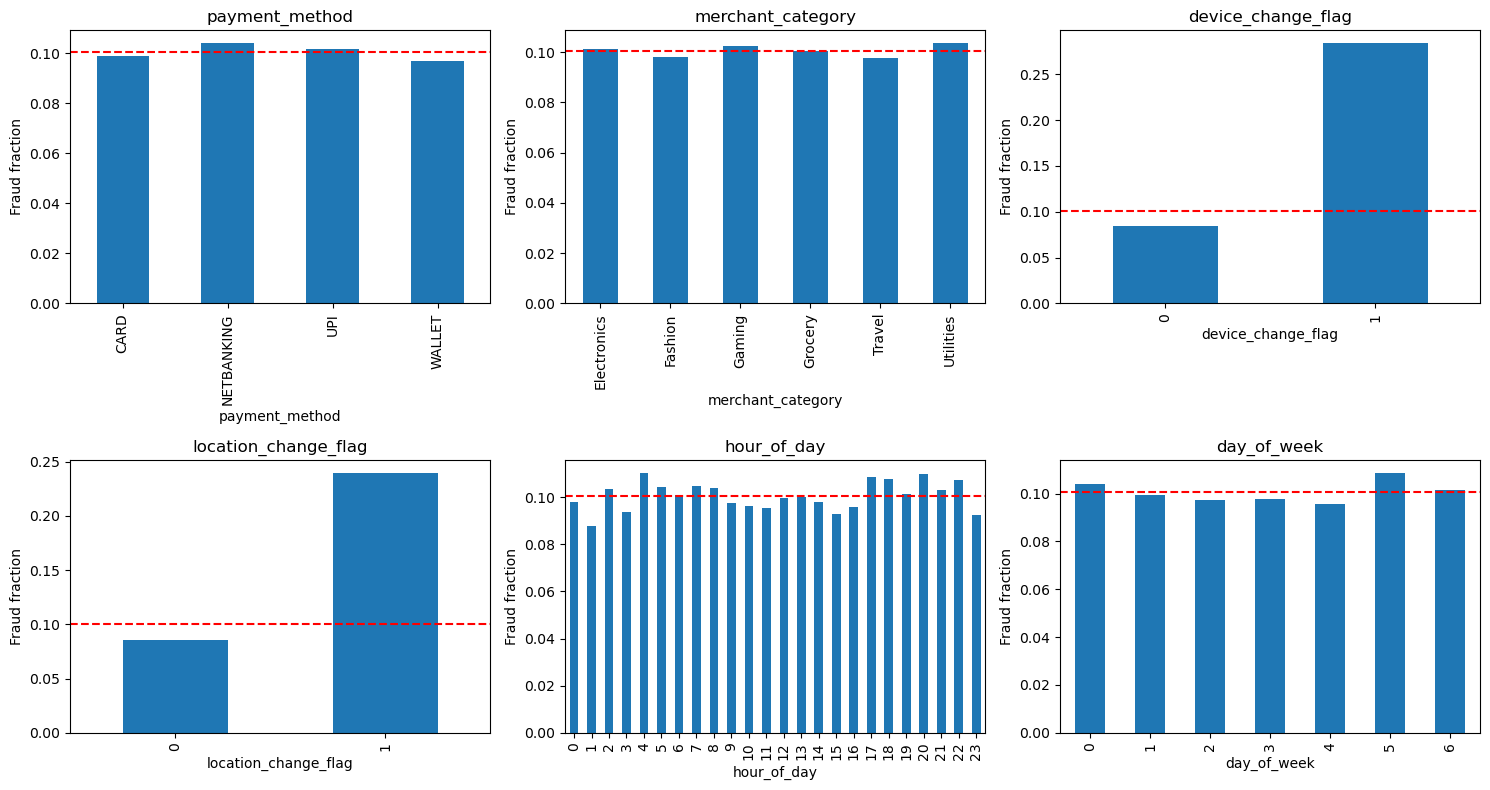

In [5]:
print(f'Sample fraud prevalence: {data.is_fraud.mean():.2%}')
print(data.groupby('is_fraud').amount.agg(['count', 'sum', 'mean']).to_string())
columns = ['payment_method', 'merchant_category', 'device_change_flag',
           'location_change_flag', 'hour_of_day', 'day_of_week']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for axis, column in zip(axes.flat, columns):
    data.groupby(column).is_fraud.mean().plot.bar(ax=axis)
    axis.axhline(data.is_fraud.mean(), color='red', linestyle='--')
    axis.set_title(column)
    axis.set_ylabel('Fraud fraction')
plt.tight_layout()
plt.show()

## 4. Point-in-Time Behavioral Features
Compute rolling velocity and entity-familiarity features strictly from prior timestamps to prevent future leakage. Simultaneous transactions are isolated, and target labels are never used.

In [6]:
from collections import defaultdict, deque

import numpy as np
import pandas as pd

def historical_features(frame):
    device_users = defaultdict(set)
    pair_counts = defaultdict(int)
    merchant_counts = defaultdict(int)
    customer_counts = defaultdict(int)
    windows = defaultdict(deque)
    last_seen = {}
    rows = []

    for timestamp, batch in frame.groupby("event_time", sort=True):
        # Compute features using strictly prior state
        for row in batch.itertuples():
            customer = row.customer_id
            window = windows[customer]

            while window and window[0] < timestamp - pd.Timedelta(hours=24):
                window.popleft()

            if customer in last_seen:
                elapsed = (
                    timestamp - last_seen[customer]
                ).total_seconds() / 60
            else:
                elapsed = np.nan

            rows.append({
                "index": row.Index,
                "prior_device_customers": len(device_users[row.device_id]),
                "prior_device_uses": pair_counts[(customer, row.device_id)],
                "prior_merchant_uses": merchant_counts[
                    (customer, row.merchant_id)
                ],
                "prior_customer_transactions": customer_counts[customer],
                "minutes_since_previous": elapsed,
                "sample_velocity_5m": sum(
                    t >= timestamp - pd.Timedelta(minutes=5)
                    for t in window
                ),
                "sample_velocity_1h": sum(
                    t >= timestamp - pd.Timedelta(hours=1)
                    for t in window
                ),
                "sample_velocity_24h": len(window)
            })

        # Update historical state after scoring this timestamp
        for row in batch.itertuples():
            customer = row.customer_id

            device_users[row.device_id].add(customer)
            pair_counts[(customer, row.device_id)] += 1
            merchant_counts[(customer, row.merchant_id)] += 1
            customer_counts[customer] += 1
            windows[customer].append(timestamp)
            last_seen[customer] = timestamp

    return (
        pd.DataFrame(rows)
        .set_index("index")
        .sort_index()
        .rename_axis(index=None)
    )

# Build historical features and join to dataset
history = historical_features(data)

features = data.join(history.copy())

# Leakage test: verify early-period features are invariant to future rows
cutoff_position = min(999, len(data) - 1)
cutoff_time = data["event_time"].iloc[cutoff_position]
prefix = data.loc[data["event_time"] <= cutoff_time]

prefix_history = historical_features(prefix).rename_axis(index=None)

full_history_subset = (
    history.loc[prefix.index]
    .copy()
    .rename_axis(index=None)
)

pd.testing.assert_frame_equal(
    prefix_history,
    full_history_subset
)

print("Passed: future rows do not alter historical prefix features.")

Passed: future rows do not alter historical prefix features.


### 4.1 Derived Risk & Interaction Features
Create recency, amount-deviation, novelty, and weighted composite risk features.

In [7]:
features['new_device_flag'] = features.prior_device_uses.eq(0).astype(int)
features['new_merchant_flag'] = features.prior_merchant_uses.eq(0).astype(int)
features['device_familiarity'] = features.prior_device_uses / features.prior_customer_transactions.replace(0, np.nan)
features['amount_deviation_ratio'] = features.amount / (features.avg_amount_last_24h + 1)
features['amount_difference'] = features.amount - features.avg_amount_last_24h
features['rapid_retry_flag'] = features.minutes_since_previous.le(5).astype(int)
features['dual_shift_flag'] = features.device_change_flag * features.location_change_flag
features['late_night_flag'] = features.hour_of_day.between(0, 5).astype(int)
features['log_amount'] = np.log1p(features.amount)
features['customer_risk_history'] = 2 * features.past_fraud_count_customer + features.past_disputes_customer
features['merchant_risk_amount'] = features.merchant_historical_fraud_rate * features.log_amount
features['combined_risk_index'] = (
    .30 * features.ip_address_risk_score + .25 * features.device_change_flag
    + .20 * features.location_change_flag + .10 * features.is_international
    + .10 * features.merchant_historical_fraud_rate + .05 * (1 - features.otp_success_rate_customer)
)
print('Added feature columns:', len(set(features) - set(data)))

Added feature columns: 20


## 5. Chronological Split
Partition data by timestamp into Train (55%), Calibration (15%), Validation (15%), and Holdout Test (15%) sets without splitting simultaneous transactions.

In [8]:
cut1, cut2, cut3 = [features.event_time.iloc[int(len(features) * fraction)] for fraction in [.55, .70, .85]]
parts = {
    'train': features[features.event_time.lt(cut1)],
    'calibration': features[features.event_time.ge(cut1) & features.event_time.lt(cut2)],
    'validation': features[features.event_time.ge(cut2) & features.event_time.lt(cut3)],
    'test': features[features.event_time.ge(cut3)]
}
exclude = ['transaction_id', 'customer_id', 'device_id', 'merchant_id', 'timestamp', 'event_time', 'is_fraud']
feature_columns = [column for column in features if column not in exclude]
X = {name: frame[feature_columns] for name, frame in parts.items()}
y = {name: frame.is_fraud for name, frame in parts.items()}
for name, frame in parts.items():
    assert frame.is_fraud.nunique() == 2
    print(name, len(frame), frame.event_time.min(), frame.event_time.max(), f'fraud={frame.is_fraud.mean():.2%}')

train 27500 2024-01-01 00:01:00 2024-02-19 14:58:00 fraud=9.85%
calibration 7500 2024-02-19 15:00:00 2024-03-03 23:04:00 fraud=10.16%
validation 7500 2024-03-03 23:06:00 2024-03-17 14:55:00 fraud=10.67%
test 7500 2024-03-17 14:56:00 2024-03-30 23:55:00 fraud=10.08%


## 6. Preprocessing Pipeline & Candidate Models
Build a training-only preprocessing pipeline (imputation, scaling, one-hot encoding) and define three class-balanced baseline classifiers.

In [9]:
categorical = X['train'].select_dtypes(include='object').columns.tolist()
numeric = [column for column in feature_columns if column not in categorical]

def preprocessor():
    return ColumnTransformer([
        ('numeric', make_pipeline(SimpleImputer(strategy='median', add_indicator=True), StandardScaler()), numeric),
        ('category', make_pipeline(SimpleImputer(strategy='most_frequent'),
                                  OneHotEncoder(handle_unknown='ignore', sparse_output=False)), categorical)
    ])

candidates = {
    'Logistic regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEED),
    'Random forest': RandomForestClassifier(n_estimators=60, max_depth=9, min_samples_leaf=25,
                                            class_weight='balanced', n_jobs=2, random_state=SEED),
    'Histogram boosting': HistGradientBoostingClassifier(max_iter=60, max_depth=4, learning_rate=.05,
                                                        class_weight='balanced', early_stopping=False, random_state=SEED)
}

def log_odds(probabilities):
    clipped = np.clip(probabilities, 1e-6, 1 - 1e-6)
    return np.log(clipped / (1 - clipped)).reshape(-1, 1)

## 7. Model Training, Calibration & Selection
Fit each model on the training split, calibrate probabilities via Platt scaling on the calibration split, and select the best model using validation Average Precision.

In [10]:
trained = {}
comparison_rows = []
for name, classifier in candidates.items():
    started = time.perf_counter()
    pipeline = make_pipeline(preprocessor(), classifier)
    pipeline.fit(X['train'], y['train'])

    calibration_scores = pipeline.predict_proba(X['calibration'])[:, 1]
    calibrator = LogisticRegression(C=1e6, max_iter=1000)
    calibrator.fit(log_odds(calibration_scores), y['calibration'])

    raw_scores = pipeline.predict_proba(X['validation'])[:, 1]
    scores = calibrator.predict_proba(log_odds(raw_scores))[:, 1]
    trained[name] = (pipeline, calibrator)
    comparison_rows.append({
        'model': name,
        'validation_AP': average_precision_score(y['validation'], scores),
        'validation_ROC_AUC': roc_auc_score(y['validation'], scores),
        'calibrated_Brier': brier_score_loss(y['validation'], scores),
        'raw_Brier': brier_score_loss(y['validation'], raw_scores),
        'seconds': time.perf_counter() - started
    })
    print('Trained:', name)
comparison = pd.DataFrame(comparison_rows).sort_values('validation_AP', ascending=False)
print(comparison.to_string(index=False))
comparison.to_csv(RESULTS / 'model_comparison.csv', index=False)

Trained: Logistic regression
Trained: Random forest
Trained: Histogram boosting
              model  validation_AP  validation_ROC_AUC  calibrated_Brier  raw_Brier  seconds
 Histogram boosting       0.216778            0.695969          0.090246   0.215643 3.206216
Logistic regression       0.215616            0.696292          0.090689   0.216980 2.024089
      Random forest       0.212469            0.691602          0.090535   0.195048 1.681592


In [11]:
selected_name = comparison.iloc[0]['model']
selected_pipeline, selected_calibrator = trained[selected_name]

def score_transactions(frame):
    raw = selected_pipeline.predict_proba(frame)[:, 1]
    return selected_calibrator.predict_proba(log_odds(raw))[:, 1]

validation_scores = score_transactions(X['validation'])
print('Selected model:', selected_name)

Selected model: Histogram boosting


## 8. Decision Thresholds & Routing Policy
Select a binary threshold maximizing net savings under a 10% validation false-positive cap, set separate quantile-based OTP/review thresholds, and run an unconstrained cost-sensitivity sweep.

In [12]:
FP_COST = 150.0

# Operational and cost assumptions
MAX_FPR = 0.10
INTERVENTION_BUDGET = 0.15
REVIEW_BUDGET = 0.03

MIN_BLOCK_PRECISION = 0.90
MIN_BLOCK_COUNT = 30

labels = y["validation"].to_numpy()
amounts = parts["validation"]["amount"].to_numpy()
validation_scores = np.asarray(validation_scores)

assert np.isfinite(validation_scores).all()
assert (
    (validation_scores >= 0)
    & (validation_scores <= 1)
).all()

fraud_count = int((labels == 1).sum())
genuine_count = int((labels == 0).sum())

assert fraud_count > 0
assert genuine_count > 0

threshold_rows = []

threshold_grid = np.append(
    np.linspace(0, 1, 201),
    1.000001
)

for threshold in threshold_grid:
    flagged = validation_scores >= threshold

    tp = int((flagged & (labels == 1)).sum())
    fp = int((flagged & (labels == 0)).sum())
    fn = fraud_count - tp
    tn = genuine_count - fp

    flagged_fraud_amount = float(
        amounts[flagged & (labels == 1)].sum()
    )

    threshold_rows.append({
        "threshold": float(threshold),
        "count": int(flagged.sum()),
        "true_positive": tp,
        "false_positive": fp,
        "false_negative": fn,
        "true_negative": tn,
        "precision": tp / max(tp + fp, 1),
        "recall": tp / fraud_count,
        "false_positive_rate": fp / genuine_count,
        "flagged_share": float(flagged.mean()),
        "flagged_fraud_amount_INR": flagged_fraud_amount,
        "optimistic_savings_INR": (
            flagged_fraud_amount - FP_COST * fp
        )
    })

threshold_table = pd.DataFrame(threshold_rows)

# Constrained binary threshold (max savings under MAX_FPR)
feasible = threshold_table.loc[
    threshold_table["false_positive_rate"].le(MAX_FPR)
].copy()

assert not feasible.empty, (
    "No threshold satisfies the validation false-positive constraint."
)

best_row = feasible.sort_values(
    ["optimistic_savings_INR", "threshold"],
    ascending=[False, False]
).iloc[0]

binary_threshold = float(best_row["threshold"])

# Tiered operational routing thresholds
otp_threshold = float(
    np.quantile(
        validation_scores,
        1 - INTERVENTION_BUDGET
    )
)

review_threshold = float(
    np.quantile(
        validation_scores,
        1 - REVIEW_BUDGET
    )
)

eligible_blocks = threshold_table.loc[
    threshold_table["precision"].ge(MIN_BLOCK_PRECISION)
    & threshold_table["count"].ge(MIN_BLOCK_COUNT)
    & threshold_table["threshold"].ge(review_threshold)
]

automatic_block_enabled = not eligible_blocks.empty

block_threshold = (
    float(eligible_blocks["threshold"].min())
    if automatic_block_enabled
    else 1.000001
)

policy = {
    "binary_threshold": binary_threshold,
    "max_validation_binary_fpr": MAX_FPR,
    "otp_threshold": otp_threshold,
    "review_threshold": review_threshold,
    "block_threshold": block_threshold,
    "automatic_block_enabled": automatic_block_enabled
}

print("SELECTED POLICY")
print(json.dumps(policy, indent=2))

print("\nCONSTRAINED BINARY COST-SCENARIO RESULT")
print(
    best_row[
        [
            "threshold",
            "precision",
            "recall",
            "false_positive_rate",
            "flagged_share",
            "optimistic_savings_INR"
        ]
    ].to_string()
)

print(
    f"\nThe binary threshold satisfies a "
    f"{MAX_FPR:.0%} validation false-positive cap."
)

print(
    "This is an illustrative constraint, not a guarantee "
    "of future performance."
)

print(
    "The binary scenario is separate from the OTP/review policy."
)

if best_row["flagged_share"] > INTERVENTION_BUDGET:
    print(
        "WARNING: Binary flagged traffic exceeds the separate "
        "illustrative operational intervention budget."
    )

print(
    "\nOTP/review budget targets are approximate. "
    "Score ties and future score drift can change action volumes."
)

# Unconstrained cost-sensitivity grid
sensitivity_rows = []

for prevention_rate in [0.25, 0.50, 0.75, 1.00]:
    for false_positive_cost in [150.0, 500.0, 1500.0]:
        scenario = threshold_table.copy()

        scenario["estimated_net_benefit_INR"] = (
            prevention_rate * scenario["flagged_fraud_amount_INR"]
            - false_positive_cost * scenario["false_positive"]
        )

        chosen = scenario.sort_values(
            ["estimated_net_benefit_INR", "threshold"],
            ascending=[False, False]
        ).iloc[0]

        sensitivity_rows.append({
            "assumed_prevention_rate": prevention_rate,
            "assumed_false_positive_cost_INR": false_positive_cost,
            "selected_threshold": float(chosen["threshold"]),
            "precision": float(chosen["precision"]),
            "recall": float(chosen["recall"]),
            "false_positive_rate": float(
                chosen["false_positive_rate"]
            ),
            "flagged_share": float(chosen["flagged_share"]),
            "estimated_net_benefit_INR": float(
                chosen["estimated_net_benefit_INR"]
            )
        })

sensitivity_table = pd.DataFrame(sensitivity_rows)

print("\nUNCONSTRAINED VALIDATION COST-SENSITIVITY SCENARIOS")
print(sensitivity_table.to_string(index=False))

print(
    "\nSensitivity scenarios do not overwrite the selected policy. "
    "Costs and prevention effectiveness are illustrative assumptions. "
    "Estimated benefit excludes intervention costs on fraud cases, "
    "fixed operating costs, and other unmeasured effects."
)

threshold_table.to_csv(
    RESULTS / "validation_thresholds.csv",
    index=False
)

sensitivity_table.to_csv(
    RESULTS / "cost_sensitivity.csv",
    index=False
)

SELECTED POLICY
{
  "binary_threshold": 0.23500000000000001,
  "max_validation_binary_fpr": 0.1,
  "otp_threshold": 0.19352584434889472,
  "review_threshold": 0.2979173302782844,
  "block_threshold": 1.000001,
  "automatic_block_enabled": false
}

CONSTRAINED BINARY COST-SCENARIO RESULT
threshold                 2.350000e-01
precision                 2.567568e-01
recall                    2.850000e-01
false_positive_rate       9.850746e-02
flagged_share             1.184000e-01
optimistic_savings_INR    2.145959e+06

The binary threshold satisfies a 10% validation false-positive cap.
This is an illustrative constraint, not a guarantee of future performance.
The binary scenario is separate from the OTP/review policy.

OTP/review budget targets are approximate. Score ties and future score drift can change action volumes.

UNCONSTRAINED VALIDATION COST-SENSITIVITY SCENARIOS
 assumed_prevention_rate  assumed_false_positive_cost_INR  selected_threshold  precision  recall  false_positive_rat

## 9. Holdout Test Evaluation
Evaluate the frozen model and validation-selected threshold once on the chronological test set across ranking, calibration, and classification metrics.

ROC_AUC              0.709207
average_precision    0.225511
Brier_score          0.084722
              precision    recall  f1-score   support

           0     0.9228    0.9069    0.9147      6744
           1     0.2798    0.3228    0.2998       756

    accuracy                         0.8480      7500
   macro avg     0.6013    0.6148    0.6073      7500
weighted avg     0.8579    0.8480    0.8528      7500



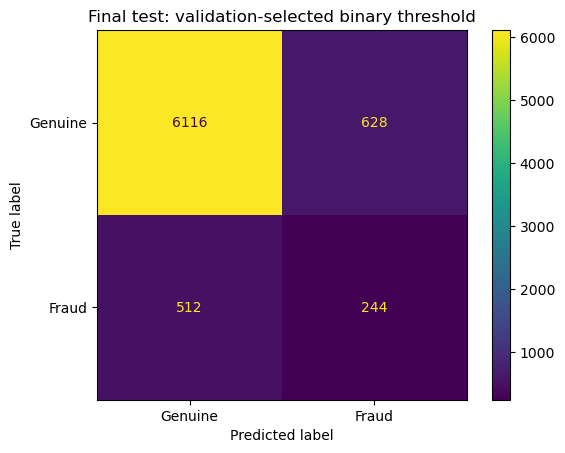

In [13]:
test_scores = score_transactions(X['test'])
test_predictions = test_scores >= binary_threshold
metrics = {
    'ROC_AUC': roc_auc_score(y['test'], test_scores),
    'average_precision': average_precision_score(y['test'], test_scores),
    'Brier_score': brier_score_loss(y['test'], test_scores)
}
print(pd.Series(metrics).to_string())
print(classification_report(y['test'], test_predictions, digits=4, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y['test'], test_predictions, display_labels=['Genuine', 'Fraud'])
plt.title('Final test: validation-selected binary threshold')
plt.show()
pd.DataFrame([metrics]).to_csv(RESULTS / 'test_metrics.csv', index=False)

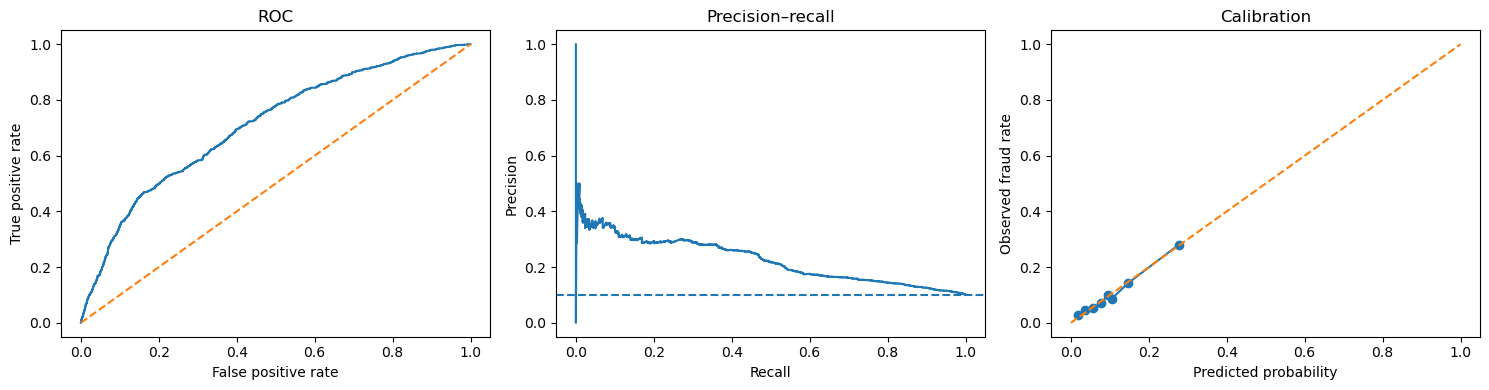

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fpr, tpr, _ = roc_curve(y['test'], test_scores)
axes[0].plot(fpr, tpr)
axes[0].plot([0, 1], [0, 1], '--')
axes[0].set(title='ROC', xlabel='False positive rate', ylabel='True positive rate')
precision, recall, _ = precision_recall_curve(y['test'], test_scores)
axes[1].plot(recall, precision)
axes[1].axhline(y['test'].mean(), linestyle='--')
axes[1].set(title='Precision–recall', xlabel='Recall', ylabel='Precision')
observed, predicted = calibration_curve(y['test'], test_scores, n_bins=8, strategy='quantile')
axes[2].plot(predicted, observed, 'o-')
axes[2].plot([0, 1], [0, 1], '--')
axes[2].set(title='Calibration', xlabel='Predicted probability', ylabel='Observed fraud rate')
plt.tight_layout()
plt.show()

## 10. Transaction Scoring & Tiered Action Routing
Assign tiered operational actions (`Auto-approve`, `OTP challenge`, `Analyst review`) to test transactions and export scored outputs.

In [15]:
scored = parts['test'][['transaction_id', 'timestamp', 'customer_id', 'device_id',
    'merchant_id', 'amount', 'payment_method', 'merchant_category', 'is_fraud']].copy()
scored['fraud_risk_score'] = test_scores
scored['binary_prediction'] = test_predictions.astype(int)
scored['proposed_action'] = np.select(
    [test_scores >= block_threshold, test_scores >= review_threshold, test_scores >= otp_threshold],
    ['Hard block (proposed)', 'Analyst review', 'OTP challenge'], default='Auto-approve'
)
scored['fraud_exposure_INR'] = scored.amount * scored.is_fraud
summary = scored.groupby('proposed_action').agg(
    transactions=('is_fraud', 'size'), fraud_cases=('is_fraud', 'sum'),
    observed_fraud_rate=('is_fraud', 'mean'), fraud_exposure_INR=('fraud_exposure_INR', 'sum')
)
summary['traffic_share'] = summary.transactions / len(scored)
summary['genuine_cases'] = summary.transactions - summary.fraud_cases
print(summary.to_string())
scored.to_csv(RESULTS / 'scored_transactions.csv', index=False)
scored.to_excel(RESULTS / 'scored_transactions.xlsx', index=False)
summary.to_csv(RESULTS / 'action_summary.csv')

                 transactions  fraud_cases  observed_fraud_rate  fraud_exposure_INR  traffic_share  genuine_cases
proposed_action                                                                                                  
Analyst review            217           74             0.341014           771824.56       0.028933            143
Auto-approve             6416          469             0.073099          4717590.26       0.855467           5947
OTP challenge             867          213             0.245675          2267501.25       0.115600            654


## 11. Feature Importance & Model Packaging
Measure validation permutation importance (Average Precision) and save the trained model bundle alongside its scoring contract.

In [16]:
from sklearn.inspection import permutation_importance

# Permutation importance on full validation split
importance = permutation_importance(
    estimator=selected_pipeline,
    X=X["validation"],
    y=y["validation"],
    scoring="average_precision",
    n_repeats=10,
    random_state=SEED,
    n_jobs=2
)

drivers = pd.DataFrame({
    "feature": feature_columns,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std
})

# Variability band (+/- 2 std across repeats)
drivers["mean_minus_2std"] = (
    drivers["importance_mean"]
    - 2 * drivers["importance_std"]
)

drivers["mean_plus_2std"] = (
    drivers["importance_mean"]
    + 2 * drivers["importance_std"]
)

drivers = drivers.sort_values(
    "importance_mean",
    ascending=False
).reset_index(drop=True)

print("VALIDATION PERMUTATION IMPORTANCE")
print(drivers.head(15).to_string(index=False))

print(
    "\nPositive importance means permutation reduced average precision "
    "on this validation set."
)

print(
    "Near-zero or negative importance does not establish a causal "
    "relationship or prove that a feature prevents fraud."
)

print(
    "Related raw and engineered features can share or mask importance. "
    "The standard deviation measures variation across permutations, "
    "not uncertainty across future datasets."
)

drivers.to_csv(
    RESULTS / "feature_importance.csv",
    index=False
)

bundle = {
    "pipeline": selected_pipeline,
    "calibrator": selected_calibrator,
    "features": feature_columns,
    "policy": policy,
    "model": selected_name,
    "input_contract": (
        "A pandas DataFrame containing the engineered feature "
        "columns listed in 'features'."
    ),
    "historical_feature_state_included": False
}

joblib.dump(
    bundle,
    RESULTS / "model_bundle.joblib"
)

scoring_contract = {
    "required_feature_columns": feature_columns,
    "input_type": "Engineered pandas DataFrame",
    "scoring_steps": [
        "Validate the raw transaction.",
        "Retrieve prior historical state.",
        "Compute features using only information available at decision time.",
        "Apply the saved preprocessing and classifier.",
        "Apply the saved calibrator to clipped raw log odds.",
        "Apply the saved action thresholds.",
        "Update historical state after scoring."
    ],
    "calibration_probability_clip": [1e-6, 1 - 1e-6],
    "not_included": [
        "Raw-transaction API",
        "Persistent historical feature store",
        "Verified availability times for supplied historical fields",
        "Production monitoring and rollback service"
    ]
}

(RESULTS / "scoring_contract.json").write_text(
    json.dumps(scoring_contract, indent=2),
    encoding="utf-8"
)

print("\nSaved model bundle and scoring contract.")
print("Load joblib files only from trusted sources.")

VALIDATION PERMUTATION IMPORTANCE
                       feature  importance_mean  importance_std  mean_minus_2std  mean_plus_2std
           combined_risk_index         0.102588        0.004256         0.094076        0.111099
         ip_address_risk_score         0.005615        0.002194         0.001226        0.010003
               dual_shift_flag         0.003788        0.000932         0.001924        0.005652
            device_change_flag         0.003782        0.002338        -0.000893        0.008457
     otp_success_rate_customer         0.001213        0.001076        -0.000938        0.003364
        amount_deviation_ratio         0.000640        0.001194        -0.001748        0.003027
             merchant_category         0.000613        0.000440        -0.000267        0.001494
            sample_velocity_1h         0.000533        0.000349        -0.000165        0.001232
merchant_historical_fraud_rate         0.000522        0.000463        -0.000405        0.001

## 12. Batch Inference Latency Benchmark
Benchmark median scoring latency (preprocessing, prediction, and calibration) on a 1,000-row test batch.

In [17]:
batch = X['test'].iloc[:1000]
score_transactions(batch)
durations = []
for repetition in range(10):
    start = time.perf_counter()
    score_transactions(batch)
    durations.append(time.perf_counter() - start)
median_ms = float(np.median(durations) * 1000)
print(f'Median batch time for {len(batch)} rows: {median_ms:.2f} ms')
print(f'Amortized time per row: {median_ms / len(batch):.4f} ms')

Median batch time for 1000 rows: 10.70 ms
Amortized time per row: 0.0107 ms


## 13. Automated Business Report & Artifact Export
Compile test metrics, operational routing impact, top risk drivers, and deployment considerations into `business_report.md` and supporting artifacts.

In [18]:
import json
from pathlib import Path
from sklearn.metrics import confusion_matrix

RESULTS = Path(RESULTS)
RESULTS.mkdir(parents=True, exist_ok=True)

def safe_divide(numerator, denominator):
    if denominator == 0:
        return 0.0
    return float(numerator) / float(denominator)

# 1. Operational routing metrics
intervention = scored["proposed_action"].ne("Auto-approve")
fraud_mask = scored["is_fraud"].eq(1)
genuine_mask = scored["is_fraud"].eq(0)

fraud_total = int(fraud_mask.sum())
genuine_total = int(genuine_mask.sum())
intervention_count = int(intervention.sum())

routed_fraud = int(
    (intervention & fraud_mask).sum()
)

routed_genuine = int(
    (intervention & genuine_mask).sum()
)

autoapproved_fraud = int(
    (~intervention & fraud_mask).sum()
)

genuine_clear = int(
    (~intervention & genuine_mask).sum()
)

total_fraud_exposure = float(
    scored.loc[fraud_mask, "amount"].sum()
)

routed_exposure = float(
    scored.loc[
        intervention & fraud_mask,
        "amount"
    ].sum()
)

autoapproved_fraud_exposure = float(
    scored.loc[
        ~intervention & fraud_mask,
        "amount"
    ].sum()
)

operational_metrics = {
    "intervention_share": safe_divide(
        intervention_count, len(scored)
    ),
    "intervention_precision": safe_divide(
        routed_fraud, intervention_count
    ),
    "fraud_routing_recall": safe_divide(
        routed_fraud, fraud_total
    ),
    "genuine_intervention_rate": safe_divide(
        routed_genuine, genuine_total
    ),
    "genuine_autoapproval_rate": safe_divide(
        genuine_clear, genuine_total
    ),
    "fraud_exposure_routing_rate": safe_divide(
        routed_exposure, total_fraud_exposure
    )
}

# 2. Binary threshold metrics
tn, fp, fn, tp = confusion_matrix(
    y["test"],
    test_predictions,
    labels=[0, 1]
).ravel()

binary_precision = safe_divide(tp, tp + fp)
binary_recall = safe_divide(tp, tp + fn)
binary_fpr = safe_divide(fp, fp + tn)

binary_flagged_share = float(
    np.asarray(test_predictions).mean()
)

# 3. Training-period segment summary
eda_source = parts["train"]

training_fraud_rate = float(
    eda_source["is_fraud"].mean()
)

eda_columns = [
    "payment_method",
    "merchant_category",
    "device_change_flag",
    "location_change_flag"
]

segment_tables = []
insight_lines = []

for column in eda_columns:
    table = (
        eda_source
        .groupby(column, dropna=False)["is_fraud"]
        .agg(
            transactions="size",
            fraud_cases="sum",
            fraud_rate="mean"
        )
        .reset_index()
    )

    table["overall_training_fraud_rate"] = training_fraud_rate

    table["difference_percentage_points"] = (
        table["fraud_rate"] - training_fraud_rate
    ) * 100

    export_table = table.rename(
        columns={column: "segment"}
    ).copy()

    export_table.insert(0, "feature", column)

    export_table["segment"] = (
        export_table["segment"].astype(str)
    )

    segment_tables.append(export_table)

    eligible_segments = table.loc[
        table["transactions"].ge(100)
    ]

    if eligible_segments.empty:
        continue

    highest = eligible_segments.sort_values(
        ["fraud_rate", "transactions"],
        ascending=[False, False]
    ).iloc[0]

    difference = float(
        highest["difference_percentage_points"]
    )

    insight_lines.append(
        f"- {column}={highest[column]}: "
        f"{int(highest['transactions']):,} transactions, "
        f"{int(highest['fraud_cases']):,} fraud cases, "
        f"fraud rate {highest['fraud_rate']:.2%}, "
        f"{difference:+.2f} percentage points versus "
        f"the training-period overall rate "
        f"of {training_fraud_rate:.2%}."
    )

eda_segments = pd.concat(
    segment_tables,
    ignore_index=True
)

eda_segments.to_csv(
    RESULTS / "eda_segment_summary.csv",
    index=False
)

# 4. Model comparison summary
ranked_models = comparison.sort_values(
    "validation_AP",
    ascending=False
).reset_index(drop=True)

selection_text = (
    f"Selected model: {selected_name}. "
    "It had the highest average precision in this "
    "validation comparison."
)

if len(ranked_models) >= 2:
    ap_gap = float(
        ranked_models.loc[0, "validation_AP"]
        - ranked_models.loc[1, "validation_AP"]
    )

    selection_text += (
        f" Its validation average-precision advantage "
        f"over the runner-up was {ap_gap:.4f}. "
        "A single validation comparison does not establish "
        "consistent superiority on future data."
    )

# 5. Top feature drivers
positive_drivers = drivers.loc[
    drivers["importance_mean"].gt(0)
].head(5)

driver_lines = [
    (
        f"- {row.feature}: mean importance "
        f"{row.importance_mean:.4f}, "
        f"permutation standard deviation "
        f"{row.importance_std:.4f}."
    )
    for row in positive_drivers.itertuples(index=False)
]

if not driver_lines:
    driver_lines = [
        "- No feature had positive mean permutation "
        "importance in this calculation."
    ]

# 6. Assemble and export report
metrics_text = "\n".join(
    f"- {name}: {value:.4f}"
    for name, value in metrics.items()
)

report_lines = [
    "# PaySphere: Business Report",
    "",
    "## 1. Executive Summary",
    (
        "This project is a fraud-scoring prototype, "
        "not a complete production deployment."
    ),
    (
        f"The proposed operational policy intervened on "
        f"{operational_metrics['intervention_share']:.2%} "
        f"of test transactions and routed "
        f"{operational_metrics['fraud_routing_recall']:.2%} "
        "of observed fraud cases."
    ),
    (
        "Routing fraud to OTP or analyst review is not "
        "the same as preventing fraud."
    ),
    "",
    "## 2. Selected Model",
    selection_text,
    "",
    "## 3. Dataset and Evaluation Scope",
    f"Dataset transactions: {len(data):,}.",
    f"Sample fraud prevalence: {data['is_fraud'].mean():.2%}.",
    f"Final test transactions: {len(scored):,}.",
    f"Final test fraud cases: {fraud_total:,}.",
    f"Final test genuine transactions: {genuine_total:,}.",
    (
        "The brief describes fraud prevalence below 0.5%, "
        "which differs materially from this dataset."
    ),
    (
        "Train, calibration, validation, and test periods "
        "are separated chronologically."
    ),
    (
        "This revised report uses the existing holdout. "
        "Its results were inspected during review, so this "
        "is not a newly untouched evaluation."
    ),
    "",
    "## 4. Exploratory Fraud Findings",
    (
        "The findings below use training-period data and "
        "describe associations, not causal effects. "
        "For each feature, the highest-rate segment with "
        "at least 100 transactions is shown. This is "
        "descriptive selection, not a significance test."
    ),
    *insight_lines,
    "",
    "## 5. Test Ranking and Probability Metrics",
    metrics_text,
    (
        "Interpret these metrics alongside operational "
        "workload and fraud-routing results."
    ),
    "",
    "## 6. Proposed Operational Policy",
    f"Transactions routed for intervention: {intervention_count:,}.",
    (
        f"Intervention share: "
        f"{operational_metrics['intervention_share']:.2%}."
    ),
    f"Fraud cases routed: {routed_fraud:,} of {fraud_total:,}.",
    (
        f"Fraud-routing recall: "
        f"{operational_metrics['fraud_routing_recall']:.2%}."
    ),
    (
        f"Intervention precision: "
        f"{operational_metrics['intervention_precision']:.2%}."
    ),
    (
        f"Genuine transactions routed: "
        f"{routed_genuine:,} of {genuine_total:,}."
    ),
    (
        f"Genuine-transaction intervention rate: "
        f"{operational_metrics['genuine_intervention_rate']:.2%}."
    ),
    (
        f"Genuine transactions auto-approved: "
        f"{genuine_clear:,} of {genuine_total:,} "
        f"({operational_metrics['genuine_autoapproval_rate']:.2%})."
    ),
    f"Fraud cases auto-approved: {autoapproved_fraud:,}.",
    (
        f"Fraud exposure routed: INR {routed_exposure:,.2f} "
        f"({operational_metrics['fraud_exposure_routing_rate']:.2%} "
        "of observed test fraud value)."
    ),
    (
        f"Fraud exposure auto-approved: "
        f"INR {autoapproved_fraud_exposure:,.2f}."
    ),
    (
        "Substantial fraud remains auto-approved. Routed "
        "exposure is not demonstrated prevented loss."
    ),
    "",
    "### Action-level results",
    "```text",
    summary.to_string(),
    "```",
    "",
    "## 7. Constrained Binary Cost Scenario",
    f"Binary threshold: {binary_threshold:.4f}.",
    f"True positives: {tp:,}.",
    f"False positives: {fp:,}.",
    f"False negatives: {fn:,}.",
    f"True negatives: {tn:,}.",
    f"Precision: {binary_precision:.2%}.",
    f"Recall: {binary_recall:.2%}.",
    f"False-positive rate: {binary_fpr:.2%}.",
    f"Flagged traffic share: {binary_flagged_share:.2%}.",
    (
        f"The binary threshold maximizes illustrative savings "
        f"subject to a {MAX_FPR:.0%} validation false-positive cap. "
        "This is an assumed constraint, not an approved company "
        "requirement or a guarantee of future performance."
    ),
    (
        "The calculation assumes perfect prevention of flagged "
        f"fraud and INR {FP_COST:,.0f} per flagged genuine "
        "transaction. These are illustrative assumptions, "
        "not demonstrated financial outcomes."
    ),
    (
        "The validation false-positive cap applies only to "
        "the binary scenario, not to OTP/review routing."
    ),
    (
        "The cost-sensitivity table explores separate, "
        "unconstrained scenarios. It does not overwrite "
        "the selected constrained binary threshold."
    ),
    "",
    "## 8. Selected Thresholds",
    "```json",
    json.dumps(policy, indent=2),
    "```",
    (
        "OTP and review thresholds reflect illustrative "
        "capacity targets. Ties and future score drift "
        "can change realized intervention volumes."
    ),
    "",
    "## 9. Model Interpretation",
    *driver_lines,
    (
        "Importance uses validation average precision. "
        "Correlated features complicate attribution. "
        "Permutation variability is not a confidence "
        "interval for future performance."
    ),
    "",
    "## 10. Data and Leakage Limitations",
    (
        "Historical count and average corrections assume "
        "the same preceding 24-hour transaction population."
    ),
    (
        "Supplied historical fraud, dispute, and merchant "
        "fraud-rate fields have unverified decision-time "
        "availability. This is a provenance risk, "
        "not proof of leakage."
    ),
    (
        "A validation-only comparison excluding these inputs "
        "and their derived features remains recommended."
    ),
    (
        "Entity master tables were not supplied, preventing "
        "full foreign-key validation."
    ),
    (
        "Observed rolling histories may be incomplete and "
        "describe the sample rather than all customer traffic."
    ),
    (
        "Do not extrapolate sample probabilities or "
        "financial estimates directly to production."
    ),
    "",
    "## 11. Deployment Scope",
    (
        "Scoring flow: raw transaction -> validation -> "
        "historical feature retrieval -> preprocessing -> "
        "classifier -> calibration -> action policy."
    ),
    (
        "The saved bundle expects engineered features. "
        "A raw-transaction API and persistent historical "
        "feature store are not included."
    ),
    (
        "Device locking is not implemented. Automatic blocking "
        "is disabled unless its validation eligibility rule is met."
    ),
    "",
    "## 12. Recommended Next Steps",
    (
        "Verify source-field timing and label maturity. "
        "Validate intervention budgets, analyst capacity, "
        "OTP effectiveness, and customer-friction costs."
    ),
    (
        "Use shadow scoring and a controlled pilot "
        "before live automated action."
    ),
    (
        "Monitor delayed-label precision, recall, fraud value, "
        "false-positive rates, score drift, missingness, "
        "and action volumes by segment."
    ),
    (
        "For further development, reserve a new future holdout "
        "or design a walk-forward evaluation rather than "
        "repeatedly tuning to this test set."
    ),
    "",
    "## 13. Inference Timing",
    (
        f"Median batch inference time: {median_ms:.2f} ms "
        f"for {len(batch):,} rows."
    ),
    (
        "This excludes historical feature retrieval, network, "
        "queueing, and payment-gateway overhead. "
        "Batch timing is not a single-request latency guarantee."
    )
]

report = "\n".join(report_lines)

(RESULTS / "business_report.md").write_text(
    report,
    encoding="utf-8"
)

(RESULTS / "policy.json").write_text(
    json.dumps(policy, indent=2),
    encoding="utf-8"
)

pd.DataFrame([operational_metrics]).to_csv(
    RESULTS / "operational_metrics.csv",
    index=False
)

print(report)

print(
    "\nBusiness report, policy, EDA tables, "
    "and operational metrics saved."
)

# PaySphere: Business Report

## 1. Executive Summary
This project is a fraud-scoring prototype, not a complete production deployment.
The proposed operational policy intervened on 14.45% of test transactions and routed 37.96% of observed fraud cases.
Routing fraud to OTP or analyst review is not the same as preventing fraud.

## 2. Selected Model
Selected model: Histogram boosting. It had the highest average precision in this validation comparison. Its validation average-precision advantage over the runner-up was 0.0012. A single validation comparison does not establish consistent superiority on future data.

## 3. Dataset and Evaluation Scope
Dataset transactions: 50,000.
Sample fraud prevalence: 10.06%.
Final test transactions: 7,500.
Final test fraud cases: 756.
Final test genuine transactions: 6,744.
The brief describes fraud prevalence below 0.5%, which differs materially from this dataset.
Train, calibration, validation, and test periods are separated chronologically.
This revis